# Can Market Regime Detection and Financial News Sentiment Analysis Improve Dynamic Commodity Portfolio Allocation?
### A Machine Learning Approach
**Ons Jdey and Senghak Rou · ENSAE · ML for Portfolio Management and Trading · 13 November 2026**

## 1. Introduction
Commodities react to the economic environment: oil, gas and metals behave differently when volatility is high, when the dollar strengthens or when rates move. A portfolio that recognises the current *regime* could adapt its estimates of expected returns and risk. Financial news might add information that prices and macro indicators do not yet contain. We test both ideas on five commodities from three sectors: Brent crude, US natural gas, gold, silver and copper.

**Design.** All strategies are long-only, monthly-rebalanced portfolios with the same optimizer, constraints, costs and dates. Only the information used to estimate expected returns and covariances changes.

| ID | Strategy | Information conditioning the moments |
|:--|:--|:--|
| A | Equal weight | — |
| B | Markowitz | — (rolling 120-month moments) |
| C / E | Regime Markowitz (KMeans / GMM) | 15 commodity + 6 FRED features |
| G | Sentiment Markowitz | gold-news sentiment only |
| D / F | Regime + sentiment Markowitz (KMeans / GMM) | 21 market features + sentiment |

**Hypotheses**, each tested as a paired difference in Sharpe ratio: **H1** regimes improve Markowitz (C−B, E−B); **H2** sentiment alone improves Markowitz (G−B); **H3** sentiment improves regime portfolios (D−C, F−E).

**Contribution.** We build a reproducible monthly dataset joining World Bank commodity prices, FRED market indicators and a human-annotated gold-news corpus, and compare the two information sources individually and jointly in one walk-forward backtest with a two-month publication lag.

**Main results** (July 2016 – December 2018, 30 months, net of 10 bp costs):
- **H1, suggestive but fragile.** KMeans regimes raise the Sharpe ratio from 0.35 (Markowitz) to 0.68. The paired 95% interval for the difference, [0.04, 0.81], excludes zero, but the Bonferroni-corrected interval does not, and in a second period (2021–2025) the same design trails Markowitz by 0.10. GMM regimes add 0.09, which is not significant.
- **H2 and H3, not supported.** Sentiment lowers the Sharpe ratio, both alone (G−B = −0.15) and when added to regimes (D−C = −0.17, F−E = −0.03). Every interval includes zero.
- **Why.** Gold-news sentiment correlates 0.43 with same-month gold price changes but −0.12 with changes two months later, the earliest month a portfolio can use it. The headlines describe price moves rather than anticipate them.

**Reproduction.** Run all cells (Python 3.12, internet access, about one minute). Raw inputs are downloaded from immutable revisions and checked by SHA-256; no local file is needed. Tested environment:
```python
%pip install numpy==2.4.4 pandas==2.3.3 scipy==1.17.1 scikit-learn==1.9.0 matplotlib==3.10.9 openpyxl==3.1.5 pyarrow==25.0.1 requests==2.34.2
```

In [1]:
from io import BytesIO
from importlib.metadata import version
import hashlib
import sys
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter
from scipy.optimize import minimize
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown

SEED = 42
START, END = pd.Timestamp("2006-04-01"), pd.Timestamp("2018-12-01")
TRAIN_END, MODEL_END = pd.Timestamp("2012-12-01"), pd.Timestamp("2015-12-01")
EVAL_START = pd.Timestamp("2016-07-01")
LOOKBACK, LAG, PRIOR, MIN_EFFECTIVE = 120, 2, 24, 12
GAMMA, CAP, MEAN_SHRINK, COV_SHRINK, FEE_BPS = 5.0, .60, .50, .20, 10
NAMES = list("ABCDEFG")
DESCRIPTIONS = dict(zip(NAMES, ["Equal weight", "Markowitz", "KMeans regimes", "KMeans + sentiment",
                                "GMM regimes", "GMM + sentiment", "Sentiment only"]))
COLORS = dict(zip(NAMES, ["#7f7f7f", "#111111", "#1f77b4", "#2ca02c", "#ff7f0e", "#d62728", "#9467bd"]))
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": .2,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python", sys.version.split()[0], {p: version(p) for p in
      ["numpy", "pandas", "scipy", "scikit-learn", "matplotlib", "openpyxl", "pyarrow"]})

Python 3.12.7 {'numpy': '1.26.4', 'pandas': '2.2.2', 'scipy': '1.17.1', 'scikit-learn': '1.5.1', 'matplotlib': '3.9.2', 'openpyxl': '3.1.5', 'pyarrow': '16.1.0'}


## 2. Data
### 2.1 Commodity prices and market indicators
Prices are monthly averages from the [World Bank Pink Sheet](https://www.worldbank.org/en/research/commodity-markets) (nominal USD). They are benchmark prices, not futures total returns. Market indicators are four daily [FRED](https://fred.stlouisfed.org/) series: VIX (`VIXCLS`), the broad dollar index (`DTWEXBGS`), and the 10- and 2-year Treasury yields (`DGS10`, `DGS2`). They are averaged within each month, requiring at least ten valid days. The snapshots retrieved on 7 November 2026 are downloaded from [project revision `3eaa7f3`](https://github.com/onsjd/Machine-learning-for-portfolio-management/tree/3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/data) so that later vendor revisions cannot silently change the results.

In [2]:
SNAPSHOT = ("https://raw.githubusercontent.com/onsjd/Machine-learning-for-portfolio-management/"
            "3eaa7f398ac0f8cc7ea2d1a89381ad11815a900c/data/raw/")
MARKET_SOURCES = {
    "World Bank": ("world_bank_monthly.xlsx", "3c8d9d8dbb48342fdbf24777c39a8ce8964cc2fd0958f72f6779e6e4ad99cde2"),
    "VIXCLS": ("fred/VIXCLS.csv", "b587c3478ee03ccb21a8e5d7582baaa4b921ff6aaef552551f6dd9cb95a81db0"),
    "DTWEXBGS": ("fred/DTWEXBGS.csv", "1569a280c509d0e2e702c0c5fb410415e2c137748a689f430a0116dcb24bc5ed"),
    "DGS10": ("fred/DGS10.csv", "85ffdfe56808d9f340bc267c57c0d578ebae48bc73bc8763c581b891b50cac41"),
    "DGS2": ("fred/DGS2.csv", "cffee922bb4c42ad21af44f12d453c87afb52f62e6352e4aedcefc89af93ac0a"),
}

def download_verified(url, sha256):
    response = requests.get(url, timeout=90)
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != sha256:
        raise ValueError(f"Integrity check failed: {url}")
    return BytesIO(response.content)

raw = {name: download_verified(SNAPSHOT + path, sha) for name, (path, sha) in MARKET_SOURCES.items()}
wb = pd.read_excel(raw["World Bank"], sheet_name="Monthly Prices", header=4)
wb = wb.loc[wb.iloc[:, 0].astype(str).str.fullmatch(r"\d{4}M\d{2}")].copy()
wb.index = pd.to_datetime(wb.iloc[:, 0], format="%YM%m")
COMMODITIES = {"Crude oil, Brent": "brent", "Natural gas, US": "natural_gas_us",
               "Gold": "gold", "Silver": "silver", "Copper": "copper"}
prices = wb[list(COMMODITIES)].rename(columns=COMMODITIES).apply(pd.to_numeric).loc["2000-01":"2025-12"]
prices.index.name = "date"
assert prices.index.equals(pd.date_range("2000-01-01", "2025-12-01", freq="MS"))
assert np.isfinite(prices).all().all() and prices.gt(0).all().all()
ret = prices.pct_change(fill_method=None).dropna()  # simple monthly price changes, used for portfolios

fred, fred_days = {}, {}
for sid in ["VIXCLS", "DTWEXBGS", "DGS10", "DGS2"]:
    daily = pd.read_csv(raw[sid], index_col=0, parse_dates=True)
    values = pd.to_numeric(daily[sid], errors="coerce").sort_index()  # holidays stay missing
    fred_days[sid] = values.resample("MS").count()
    fred[sid] = values.resample("MS").mean().where(fred_days[sid] >= 10)
fred = pd.DataFrame(fred).loc["2000-01":"2025-12"]
fred_days = pd.DataFrame(fred_days)
print("All five market sources verified.")

All five market sources verified.


### 2.2 Gold-news sentiment
We use the [SaguaroCapital redistribution](https://huggingface.co/datasets/SaguaroCapital/sentiment-analysis-in-commodity-market-gold/blob/4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5/README.md) (revision `4423810`, CC BY-NC-ND 4.0) of the Sinha–Khandait corpus: gold-market headlines labelled by experts as positive, negative, neutral or none. We keep the supplied labels rather than train a text classifier. The two oil-news datasets listed in the course cannot replace it. `polibert/oil-sentiment-headlines` starts in 2019, has fewer than 20 headlines a month before 2022 and uses machine-generated labels, and `newsdata01/crude-oil-and-petroleum-market-news-dataset` covers only 2026. Our 120-month estimation windows need a decade of history.

We combine the two splits, parse dates strictly (day–month–year), drop undatable, out-of-window or empty records, and keep one record per date–headline pair, or none if their labels conflict. The monthly feature is the balance of directional labels over all retained headlines:
$$S_t=\frac{N_t^{+}-N_t^{-}}{N_t^{+}+N_t^{-}+N_t^{\text{neutral}}+N_t^{\text{none}}}\in[-1,1].$$

In [3]:
DATASET = "SaguaroCapital/sentiment-analysis-in-commodity-market-gold"
REVISION = "4423810af0fddf2c91a3c9634bbb6d4afdf9d5a5"
NEWS_HASHES = {"train": "65b0f4ab9e6dc2009960b762285924f440f8a551d593a5120905b763c79c1b68",
               "test": "b1a169fea3241630b293391dfe879189221896274d64f2a95fa513633a87f089"}
news_url = f"https://huggingface.co/datasets/{DATASET}/resolve/{REVISION}/data/"
raw_news = pd.concat([pd.read_parquet(download_verified(news_url + f"{split}-00000-of-00001.parquet", sha))
                      .assign(source_split=split) for split, sha in NEWS_HASHES.items()], ignore_index=True)
LABELS = ["positive", "negative", "neutral", "none"]
BINARY_COLUMNS = ["Price Direction Up", "Price Direction Constant", "Price Direction Down",
                  "Asset Comparision", "Past Information", "Future Information"]
KEYS = ["date", "headline_key"]

def clean_news(raw):
    frame = raw.copy()
    frame["date"] = pd.to_datetime(frame["Dates"].astype("string").str.strip(), format="%d-%m-%Y", errors="coerce")
    frame["headline"] = frame["News"].astype("string").str.strip()
    frame["label"] = frame["Price Sentiment"].astype("string").str.strip().str.lower()
    frame["headline_key"] = frame["headline"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
    remaining, exclusions = pd.Series(True, index=frame.index), {}
    for reason, mask in [("invalid date", frame.date.isna()),
                         ("outside window", ~frame.date.between(START, END + pd.offsets.MonthEnd(0))),
                         ("empty headline or label", frame.headline.isna() | frame.headline.eq("")
                                                      | frame.label.isna() | frame.label.eq(""))]:
        removed = remaining & mask.fillna(False)
        exclusions[reason] = int(removed.sum())
        remaining &= ~removed
    candidate = frame.loc[remaining].copy()
    assert candidate.label.isin(LABELS).all() and candidate[BINARY_COLUMNS].isin([0, 1]).all().all()
    conflicts = candidate.groupby(KEYS)[["label"] + BINARY_COLUMNS].nunique(dropna=False).gt(1).any(axis=1)
    bad = pd.MultiIndex.from_frame(candidate[KEYS]).isin(conflicts.index[conflicts])
    clean = candidate.loc[~bad].drop_duplicates(KEYS).sort_values("date", kind="stable").copy()
    exclusions["duplicate or conflicting"] = len(candidate) - len(clean)
    assert len(raw) == sum(exclusions.values()) + len(clean)
    clean["month"] = clean.date.dt.to_period("M")
    return clean, exclusions

def aggregate_news(clean):
    months = pd.period_range(START, END, freq="M")
    counts = pd.crosstab(clean["month"], clean["label"]).reindex(index=months, columns=LABELS, fill_value=0)
    total = counts.sum(axis=1)
    assert total.gt(0).all(), "Missing month: sentiment is never imputed."
    result = pd.DataFrame({"gold_news_sentiment": (counts.positive - counts.negative) / total,
                           "gold_news_count": total})
    result.index = months.to_timestamp(how="start")
    return result

news, news_exclusions = clean_news(raw_news)
monthly_news = aggregate_news(news)
assert len(raw_news) == 10570 and len(news) == 9397

### 2.3 Features and descriptive statistics
Each observation is a month. For commodity $i$, with log price change $\ell_{i,t}$, the 15 commodity features are $\ell_{i,t}$, the three-month momentum $\sum_{h=0}^{2}\ell_{i,t-h}$ and the twelve-month volatility $\sqrt{12}\,\mathrm{sd}(\ell_{i,t-11},\dots,\ell_{i,t})$. The six FRED features are log VIX, the one- and three-month log changes of the dollar, the 10-year yield, its monthly change and the 10y−2y slope. All windows are trailing, so no feature uses later data. The dollar series starts in 2006, which sets the common start to April 2006. The market vector $X^M_t$ has 21 features; $X^{M+S}_t=(X^M_t,S_t)$ adds sentiment.

,
Commodity months (Jan 2000-Dec 2025),"312 x 5 assets, no missing or non-positive price"
Feature months (Apr 2006-Dec 2018),"153, no missing value"
Headlines downloaded,"10,570"
"Excluded: invalid date, outside window, empty headline or label, duplicate or conflicting",165 / 1007 / 0 / 1
Headlines retained,"9,397"
Headlines per month,14-250 (median 44)
Headlines describing past prices,96.7%


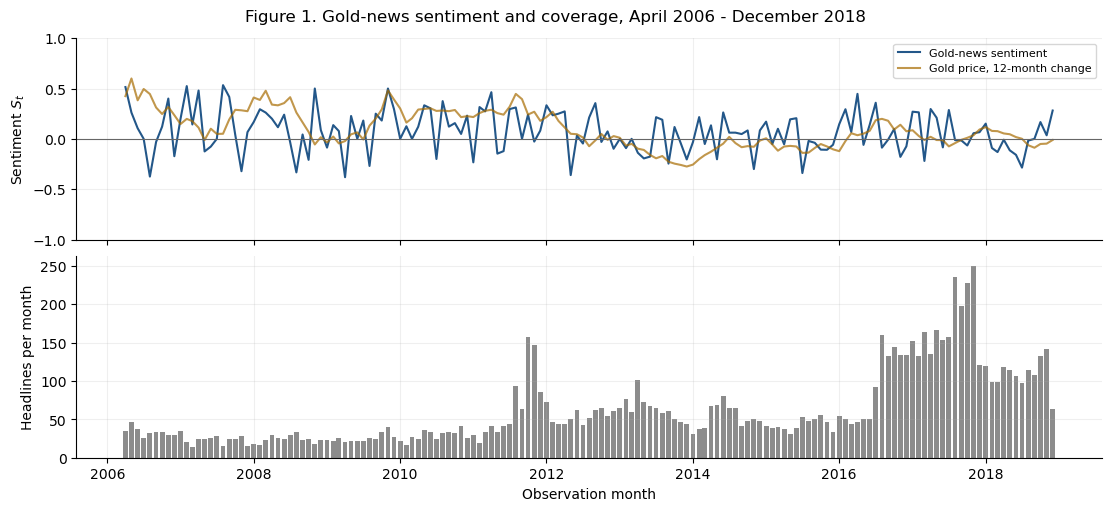

In [4]:
def market_features(price_data, macro_data):
    log_returns = np.log(price_data).diff().dropna()
    commodity = pd.concat({"r1": log_returns, "mom3": log_returns.rolling(3).sum(),
                           "vol12": log_returns.rolling(12).std() * np.sqrt(12)}, axis=1).dropna()
    commodity.columns = ["__".join(c) for c in commodity.columns]
    macro = pd.DataFrame({
        "fred_log_vix": np.log(macro_data.VIXCLS),
        "fred_dollar_return_1m": np.log(macro_data.DTWEXBGS).diff(),
        "fred_dollar_momentum_3m": np.log(macro_data.DTWEXBGS).diff(3),
        "fred_yield10_level_pp": macro_data.DGS10,
        "fred_yield10_change_1m_pp": macro_data.DGS10.diff(),
        "fred_yield_slope_10y2y_pp": macro_data.DGS10 - macro_data.DGS2})
    return commodity.join(macro).replace([np.inf, -np.inf], np.nan).dropna()

X_all = market_features(prices, fred)               # April 2006 - December 2025
common = pd.date_range(START, END, freq="MS")
X_market = X_all.loc[common]
X_sentiment = X_market.join(monthly_news[["gold_news_sentiment"]], validate="one_to_one")
S = X_sentiment["gold_news_sentiment"]
assert X_market.shape == (153, 21) and X_sentiment.shape == (153, 22)
assert np.isfinite(X_sentiment.to_numpy()).all() and fred_days.loc[common].ge(10).all().all()

display(pd.Series({
    "Commodity months (Jan 2000-Dec 2025)": f"{len(prices)} x 5 assets, no missing or non-positive price",
    "Feature months (Apr 2006-Dec 2018)": f"{len(common)}, no missing value",
    "Headlines downloaded": f"{len(raw_news):,}",
    "Excluded: " + ", ".join(news_exclusions): " / ".join(map(str, news_exclusions.values())),
    "Headlines retained": f"{len(news):,}",
    "Headlines per month": f"{monthly_news.gold_news_count.min()}-{monthly_news.gold_news_count.max()} "
                           f"(median {monthly_news.gold_news_count.median():.0f})",
    "Headlines describing past prices": f"{news['Past Information'].mean():.1%}",
}, name="").to_frame())

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, layout="constrained")
axes[0].plot(S.index, S, color="#235789")
axes[0].plot(S.index, prices.gold.pct_change(12).reindex(common), color="#A76B00", alpha=.7)
axes[0].axhline(0, color=".4", linewidth=.8)
axes[0].set(ylabel="Sentiment $S_t$", ylim=(-1, 1))
axes[0].legend(["Gold-news sentiment", "Gold price, 12-month change"], loc="upper right", fontsize=8)
axes[1].bar(monthly_news.index, monthly_news.gold_news_count, width=24, color=".55")
axes[1].set(ylabel="Headlines per month", xlabel="Observation month")
fig.suptitle("Figure 1. Gold-news sentiment and coverage, April 2006 - December 2018")
plt.show()

Sentiment moves with the gold price, and the number of headlines varies from 14 to 250 a month. Almost all headlines (97%) report price moves that have already happened, so the main question for H2 and H3 is whether $S_t$ contains anything that prices do not.

## 3. Methodology
### 3.1 Chronological split and information timing
| Sample | Months | Use |
|:--|:--|:--|
| Training | Apr 2006 – Dec 2012 (81) | fit candidate clustering models |
| Validation | Jan 2013 – Dec 2015 (36) | choose the number of regimes |
| Development | Apr 2006 – Dec 2015 (117) | refit scaler and model once, then freeze them |
| Evaluation | Jul 2016 – Dec 2018 (30) | portfolio backtest |

Monthly averages are published after the month ends, so an allocation for month $t$ uses information up to $c=t-2$ only. Its moments are estimated from the 120 most recent pairs of a lagged regime membership and a realised return, $\{(p_{u-2},\,r_u):u=c-119,\dots,c\}$, and applied to the current membership $p_c$. Features are never pre-shifted, so the lag is applied exactly once. July 2016 is the first month with 120 complete pairs.

In [5]:
train_dates = common[common <= TRAIN_END]
valid_dates = common[(common > TRAIN_END) & (common <= MODEL_END)]
dev_dates = common[common <= MODEL_END]
test_dates = pd.date_range(EVAL_START, END, freq="MS")
signal_dates = test_dates - pd.DateOffset(months=LAG)
assert [len(d) for d in (train_dates, valid_dates, dev_dates, test_dates)] == [81, 36, 117, 30]
assert dev_dates.max() < signal_dates.min()
month = lambda d: d.strftime("%b %Y")
display(pd.DataFrame([{
    "allocation": month(t), "current signal": month(t - pd.DateOffset(months=LAG)),
    "returns used": f"{month(t - pd.DateOffset(months=LAG + LOOKBACK - 1))} - {month(t - pd.DateOffset(months=LAG))}",
    "historical signals": f"{month(t - pd.DateOffset(months=2 * LAG + LOOKBACK - 1))} - {month(t - pd.DateOffset(months=2 * LAG))}"}
    for t in test_dates[[0, -1]]]).set_index("allocation"))

,current signal,returns used,historical signals
allocation,,,
Jul 2016,May 2016,Jun 2006 - May 2016,Apr 2006 - Mar 2016
Dec 2018,Oct 2018,Nov 2008 - Oct 2018,Sep 2008 - Aug 2018


### 3.2 Regimes and the sentiment state
**KMeans** splits standardised months into $k$ groups by minimising within-group squared distance and gives one-hot memberships. The **Gaussian mixture (GMM)** with diagonal covariances gives posterior probabilities instead. For $k\in\{2,3,4\}$ we pick KMeans by validation silhouette and the GMM by training BIC, using only the 21 market features. The chosen $k$ is then kept for the sentiment counterpart, so D and F differ from C and E only by the added feature. The **sentiment-only** strategy G uses two states, $\mathbf 1\{S_c>\text{median}_{\text{development}}(S)\}$: a one-dimensional regime with a threshold fixed before evaluation.

In [6]:
def select_counts(data, train_idx, valid_idx):
    scaler = StandardScaler().fit(data.loc[train_idx])
    z_train, z_valid = scaler.transform(data.loc[train_idx]), scaler.transform(data.loc[valid_idx])
    rows = []
    for k in [2, 3, 4]:
        km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(z_train)
        gm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=10, max_iter=500, random_state=SEED).fit(z_train)
        assert gm.converged_
        groups = km.predict(z_valid)
        silhouette = silhouette_score(z_valid, groups) if 1 < len(np.unique(groups)) < len(groups) else np.nan
        rows.append({"k": k, "KMeans validation silhouette": silhouette, "GMM training BIC": gm.bic(z_train)})
    table = pd.DataFrame(rows).set_index("k")
    return {"KMeans": int(table.iloc[:, 0].idxmax()), "GMM": int(table.iloc[:, 1].idxmin())}, table

def fit_memberships(data, algorithm, k, dev_idx, seed=SEED):
    """Fit the scaler and model on development months only; return memberships for every month."""
    scaler = StandardScaler().fit(data.loc[dev_idx])
    model = (KMeans(n_clusters=k, n_init=50, random_state=seed) if algorithm == "KMeans" else
             GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-4,
                             n_init=20, max_iter=500, random_state=seed))
    model.fit(scaler.transform(data.loc[dev_idx]))
    z = scaler.transform(data)
    p = np.eye(k)[model.predict(z)] if algorithm == "KMeans" else model.predict_proba(z)
    return pd.DataFrame(p, index=data.index)

def sentiment_states(threshold):
    return pd.DataFrame(np.eye(2)[S.gt(threshold).astype(int)], index=common)

selected, selection = select_counts(X_market, train_dates, valid_dates)
SPECS = {"C": ("KMeans", X_market), "D": ("KMeans", X_sentiment), "E": ("GMM", X_market), "F": ("GMM", X_sentiment)}
probabilities = {key: fit_memberships(data, alg, selected[alg], dev_dates) for key, (alg, data) in SPECS.items()}
threshold = S.loc[dev_dates].median()
probabilities["G"] = sentiment_states(threshold)
display(selection.round(3))
print(f"Selected: {selected}; sentiment threshold (development median) = {threshold:.3f}")

,KMeans validation silhouette,GMM training BIC
k,,
2,0.162,4654.454
3,0.173,4448.115
4,NaN,4443.454


Selected: {'KMeans': 3, 'GMM': 4}; sentiment threshold (development median) = 0.081


### 3.3 Conditional moments, allocation and costs
For state $j$, historical returns are weighted by $a_{u,j}=p_{u-2,j}$, which gives a weighted mean and covariance $(\mu^*_j,\Sigma^*_j)$ with effective size $n_j=(\sum_u a_{u,j})^2/\sum_u a_{u,j}^2$. Sparse states are shrunk toward the unconditional estimate $(\mu_0,\Sigma_0)$ with weight $\alpha_j=n_j/(n_j+24)$, and replaced by it when $n_j<12$. The current memberships then mix the states, keeping the dispersion between state means:
$$\mu=\sum_j p_{c,j}\,\mu_j,\qquad \Sigma=\sum_j p_{c,j}\,(\Sigma_j+\mu_j\mu_j^\top)-\mu\mu^\top .$$
As in the course's risk-model chapter, the covariance is shrunk 20% toward its diagonal, and the mean is halved because sample means are noisy: $\hat\mu=0.5\mu$, $\hat\Sigma=0.8\Sigma+0.2\,\mathrm{diag}(\Sigma)$. Strategies B to G then solve
$$\max_w\; w^\top\hat\mu-\tfrac{5}{2}\,w^\top\hat\Sigma w\quad\text{s.t.}\quad \mathbf 1^\top w=1,\;0\le w_i\le 0.6 .$$
Strategy B uses $(\mu_0,\Sigma_0)$. Holdings drift with prices between rebalances, and each trade pays 10 bp of the traded amount, $R^{net}_t=(1-0.001\,TO_t)(1+w_t^\top r_t)-1$ with $TO_t=\sum_i|w_{i,t}-\tilde w_{i,t}|$. Turnover here is two-sided, so this equals 20 bp on the course's one-sided turnover.

In [7]:
def raw_moments(values, weights=None):
    a=np.asarray(values,dtype=float)
    p=np.ones(len(a)) if weights is None else np.asarray(weights,dtype=float)
    p=p/p.sum()
    mu=p@a; centered=a-mu
    cov=(centered*p[:,None]).T@centered
    return mu,cov

def regularize(mu,cov):
    cov=(1-COV_SHRINK)*cov+COV_SHRINK*np.diag(np.diag(cov))
    cov=(cov+cov.T)/2+np.eye(len(mu))*1e-8
    return (1-MEAN_SHRINK)*mu,cov

def optimize(mu,cov,gamma=GAMMA):
    n=len(mu)
    objective=lambda w: gamma/2*(w@cov@w)-w@mu
    gradient=lambda w: gamma*(cov@w)-mu
    result=minimize(objective,np.repeat(1/n,n),jac=gradient,method='SLSQP',
        bounds=[(0,CAP)]*n,constraints={'type':'eq','fun':lambda w:w.sum()-1,
        'jac':lambda w:np.ones(n)},options={'ftol':1e-12,'maxiter':500})
    if not result.success: raise RuntimeError(result.message)
    w=result.x
    assert abs(w.sum()-1)<1e-8 and w.min()>-1e-8 and w.max()<CAP+1e-8
    return w

def blend_moments(mu_a,cov_a,mu_b,cov_b,alpha):
    mu=alpha*mu_a+(1-alpha)*mu_b
    second=alpha*(cov_a+np.outer(mu_a,mu_a))+(1-alpha)*(cov_b+np.outer(mu_b,mu_b))
    return mu,second-np.outer(mu,mu)

def conditional_moments(history,probabilities,cutoff):
    # Outcome u is paired with signal u-2; align by actual calendar month.
    signals=history.index-pd.DateOffset(months=LAG)
    ok=signals.isin(probabilities.index)
    outcomes=history.loc[ok]
    signals=signals[ok]
    prior_mu,prior_cov=raw_moments(history)
    historical_p=probabilities.loc[signals].to_numpy()
    current_p=probabilities.loc[cutoff].to_numpy()
    component_mu=[]; component_cov=[]; effective=[]; fallback=0
    for j in range(historical_p.shape[1]):
        a=historical_p[:,j]; mass=a.sum()
        neff=mass*mass/(a@a) if a@a>0 else 0.0
        effective.append(neff)
        if neff<MIN_EFFECTIVE:
            mu,cov=prior_mu,prior_cov; fallback+=1
        else:
            cm,cc=raw_moments(outcomes,a)
            mu,cov=blend_moments(cm,cc,prior_mu,prior_cov,neff/(neff+PRIOR))
        component_mu.append(mu);component_cov.append(cov)
    means=np.array(component_mu)
    mu=current_p@means
    second=sum(p*(c+np.outer(m,m)) for p,m,c in zip(current_p,means,component_cov))
    cov=second-np.outer(mu,mu)
    return mu,cov,{'effective_current':float(current_p@np.array(effective)),
                  'fallback_components':fallback,'latest_outcome':history.index.max()}

In [8]:
def allocate(return_data, memberships, dates, model_end):
    """Walk-forward target weights for A, B and every membership table; information stops at t - LAG."""
    weights, audit = {key: [] for key in ["A", "B", *memberships]}, []
    for date in dates:
        cutoff = date - pd.DateOffset(months=LAG)
        history = return_data.loc[:cutoff].tail(LOOKBACK)
        signals = history.index - pd.DateOffset(months=LAG)
        assert len(history) == LOOKBACK and history.index.max() == cutoff and cutoff > model_end
        weights["A"].append(np.full(return_data.shape[1], 1 / return_data.shape[1]))
        weights["B"].append(optimize(*regularize(*raw_moments(history))))
        for key, p in memberships.items():
            assert signals.isin(p.index).all()  # always a full window of 120 pairs
            mu, cov, info = conditional_moments(history, p, cutoff)
            weights[key].append(optimize(*regularize(mu, cov)))
            audit.append({"strategy": key, "date": date, **info})
    weights = {key: pd.DataFrame(rows, index=dates, columns=return_data.columns) for key, rows in weights.items()}
    for w in weights.values():
        np.testing.assert_allclose(w.sum(axis=1), 1, atol=1e-8)
        assert w.min().min() >= -1e-8 and w.max().max() <= CAP + 1e-8
    return weights, pd.DataFrame(audit)

def backtest(weight_table,fee_bps):
    pretrade=np.zeros(ret.shape[1]); rows=[]
    for date,wrow in weight_table.iterrows():
        w=wrow.to_numpy(); r=ret.loc[date].to_numpy()
        turnover=np.abs(w-pretrade).sum()
        gross=float(w@r);cost=fee_bps/10000*turnover
        net=(1-cost)*(1+gross)-1
        rows.append([gross,net,turnover,cost])
        pretrade=w*(1+r)/(1+gross)
    return pd.DataFrame(rows,index=weight_table.index,
                        columns=['gross_return','net_return','turnover','cost_fraction'])

def metrics(returns,turnover):
    vol=returns.std(ddof=1)*np.sqrt(12)
    curve=pd.concat([pd.Series([1.]),(1+returns).cumprod().reset_index(drop=True)],ignore_index=True)
    dd=curve/curve.cummax()-1
    return pd.Series({'CAGR':(1+returns).prod()**(12/len(returns))-1,
        'annualized_vol':vol,'Sharpe_rf0':returns.mean()*12/vol if vol>0 else np.nan,
        'max_drawdown':dd.min(),'mean_monthly_turnover':turnover.mean(),
        'positive_month_fraction':returns.gt(0).mean(),'total_return':(1+returns).prod()-1})

weights, audit = allocate(ret, probabilities, test_dates, MODEL_END)
paths = {key: backtest(weights[key], FEE_BPS) for key in NAMES}
net = pd.DataFrame({key: paths[key].net_return for key in NAMES})
initial_date = test_dates[0] - pd.DateOffset(months=1)
wealth = pd.concat([pd.DataFrame(1.0, index=[initial_date], columns=NAMES), (1 + net).cumprod()])

### 3.4 Statistical tests
For each strategy we report the annualised Sharpe ratio $\widehat{SR}=\sqrt{12}\,\bar R/s_R$ (zero risk-free rate) and its standard error under i.i.d. returns (Lo, 2002), $\mathrm{SE}\approx\sqrt{12\,(1+\widehat{SR}_m^2/2)/T}$, where $\widehat{SR}_m$ is the monthly Sharpe ratio. The hypotheses compare two strategies observed over the same months, so the main test is a **paired circular block bootstrap**. Each of 1,000 replications resamples six-month blocks of months jointly for all strategies, which preserves their correlation and some serial dependence, and recomputes the Sharpe difference. We report 95% percentile intervals, and also 99% intervals as a Bonferroni correction for testing five contrasts at the 5% level.

## 4. Empirical results
### 4.1 Performance

,Sharpe,Lo SE,t-stat,CAGR,Volatility,Max drawdown,Turnover / month
A: Equal weight,0.64,0.64,1.01,8.2%,13.7%,-10.2%,7.3%
B: Markowitz,0.35,0.63,0.55,2.8%,9.2%,-11.3%,8.9%
C: KMeans regimes,0.68,0.64,1.07,5.8%,8.8%,-11.2%,18.3%
D: KMeans + sentiment,0.51,0.64,0.81,4.4%,9.2%,-11.3%,26.4%
E: GMM regimes,0.44,0.63,0.69,4.4%,11.3%,-9.7%,26.3%
F: GMM + sentiment,0.41,0.63,0.65,4.1%,11.3%,-9.7%,27.2%
G: Sentiment only,0.20,0.63,0.31,1.5%,10.3%,-11.9%,27.6%


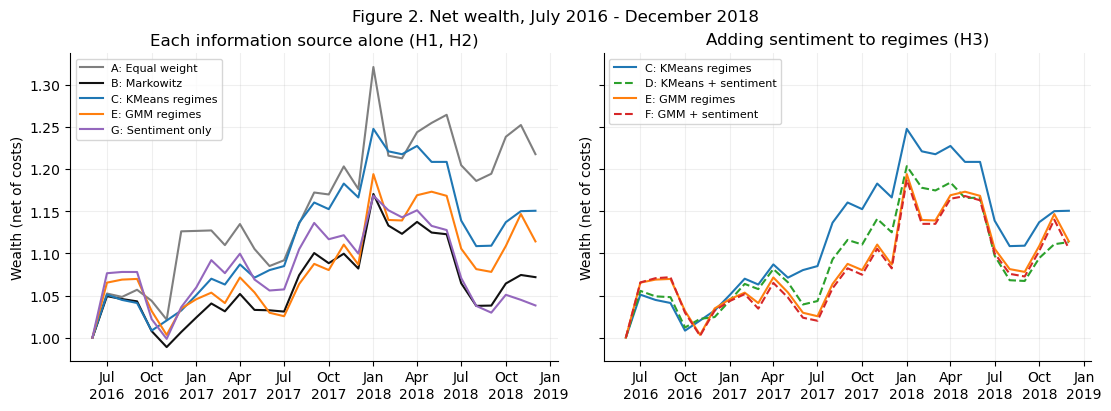

In [9]:
def sharpe(returns):
    return np.sqrt(12) * returns.mean() / returns.std(ddof=1)

summary = pd.DataFrame({key: metrics(net[key], paths[key].turnover) for key in NAMES}).T
monthly_sr = summary.Sharpe_rf0 / np.sqrt(12)
summary["Lo SE"] = np.sqrt(12 * (1 + monthly_sr**2 / 2) / len(test_dates))
summary["t-stat"] = summary.Sharpe_rf0 / summary["Lo SE"]
table = summary[["Sharpe_rf0", "Lo SE", "t-stat", "CAGR", "annualized_vol", "max_drawdown", "mean_monthly_turnover"]]
table.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
table.columns = ["Sharpe", "Lo SE", "t-stat", "CAGR", "Volatility", "Max drawdown", "Turnover / month"]
display(table.style.format({"Sharpe": "{:.2f}", "Lo SE": "{:.2f}", "t-stat": "{:.2f}", "CAGR": "{:.1%}",
                            "Volatility": "{:.1%}", "Max drawdown": "{:.1%}", "Turnover / month": "{:.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, layout="constrained")
for ax, keys, title in [(axes[0], "ABCEG", "Each information source alone (H1, H2)"),
                        (axes[1], "CDEF", "Adding sentiment to regimes (H3)")]:
    for key in keys:
        ax.plot(wealth.index, wealth[key], color=COLORS[key], label=f"{key}: {DESCRIPTIONS[key]}",
                linestyle="--" if key in "DF" else "-")
    ax.set(title=title, ylabel="Wealth (net of costs)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
    ax.legend(fontsize=8, loc="upper left")
fig.suptitle("Figure 2. Net wealth, July 2016 - December 2018")
plt.show()

Markowitz (B) holds gold at its 60% cap and has the second-lowest Sharpe ratio, ahead only of the sentiment portfolio (G). Equal weight (A) beats every optimised portfolio except KMeans regimes (C). With 30 months, each Sharpe ratio has a standard error of about 0.64, and every t-statistic is below 1.1, so no single Sharpe ratio is distinguishable from zero. The hypotheses are therefore tested on paired differences, which remove the market moves common to all strategies.

### 4.2 Hypothesis tests

,Sharpe difference,95% low,95% high,99% low,99% high
H1 C−B KMeans regimes vs Markowitz,0.335,0.041,0.808,-0.038,0.904
H1 E−B GMM regimes vs Markowitz,0.092,-0.357,0.433,-0.480,0.546
H2 G−B Sentiment vs Markowitz,-0.151,-0.492,0.147,-0.586,0.260
H3 D−C Sentiment added to KMeans,-0.168,-0.633,0.062,-0.791,0.102
H3 F−E Sentiment added to GMM,-0.028,-0.081,0.010,-0.105,0.015


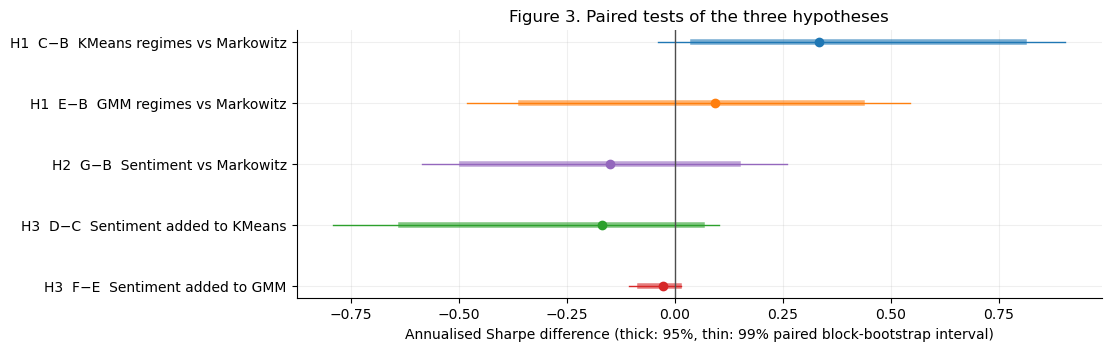

In [10]:
PAIRS = {"H1  C−B  KMeans regimes vs Markowitz": ("C", "B"), "H1  E−B  GMM regimes vs Markowitz": ("E", "B"),
         "H2  G−B  Sentiment vs Markowitz": ("G", "B"), "H3  D−C  Sentiment added to KMeans": ("D", "C"),
         "H3  F−E  Sentiment added to GMM": ("F", "E")}

def paired_bootstrap(returns, pairs, block=6, replications=1000):
    rng = np.random.default_rng(SEED)
    n, draws = len(returns), []
    for _ in range(replications):
        starts = rng.integers(0, n, size=int(np.ceil(n / block)))
        idx = np.concatenate([(s + np.arange(block)) % n for s in starts])[:n]
        sr = sharpe(returns.iloc[idx])
        draws.append([sr[a] - sr[b] for a, b in pairs.values()])
    draws, observed = np.array(draws), sharpe(returns)
    return pd.DataFrame({"Sharpe difference": [observed[a] - observed[b] for a, b in pairs.values()],
                         "95% low": np.quantile(draws, .025, axis=0), "95% high": np.quantile(draws, .975, axis=0),
                         "99% low": np.quantile(draws, .005, axis=0), "99% high": np.quantile(draws, .995, axis=0)},
                        index=list(pairs))

tests = paired_bootstrap(net, PAIRS)
display(tests.round(3))

fig, ax = plt.subplots(figsize=(11, 3.4), layout="constrained")
for i, (name, row) in enumerate(tests.iterrows()):
    color = COLORS[PAIRS[name][0]]
    ax.plot([row["99% low"], row["99% high"]], [i, i], color=color, linewidth=1)
    ax.plot([row["95% low"], row["95% high"]], [i, i], color=color, linewidth=4, alpha=.6)
    ax.scatter(row["Sharpe difference"], i, color=color, zorder=3)
ax.axvline(0, color=".3", linewidth=1)
ax.set_yticks(range(len(tests)), tests.index)
ax.invert_yaxis()
ax.set(xlabel="Annualised Sharpe difference (thick: 95%, thin: 99% paired block-bootstrap interval)",
       title="Figure 3. Paired tests of the three hypotheses")
plt.show()

Only C−B has a 95% interval that excludes zero. Its Bonferroni 99% interval, [−0.04, 0.90], includes zero, so the evidence for H1 is suggestive rather than conclusive. G−B, D−C and F−E all have negative point estimates and intervals that include zero, so sentiment never improves the allocation. The F−E interval is narrow because the extra feature barely changes the GMM states (Section 5.2).

### 4.3 What drives the differences
Following the course's attribution tools, the next table splits each strategy's gross return advantage over Markowitz by asset, $12\cdot\overline{(w_{i,t}-w^{B}_{i,t})\,r_{i,t}}$. It also splits each strategy's return into a slow **tilt**, its exponentially weighted average position with a 12-month half-life, and the **timing** residual.

In [11]:
r_test = ret.loc[test_dates]
drivers = pd.DataFrame({key: ((weights[key] - weights["B"]) * r_test).mean() * 12 for key in NAMES}).T
drivers.columns = ["Brent", "US gas", "Gold", "Silver", "Copper"]
drivers["Total vs B"] = drivers.sum(axis=1)
for key in NAMES:
    tilt = weights[key].ewm(halflife=12).mean()
    drivers.loc[key, "Tilt return"] = (tilt * r_test).sum(axis=1).mean() * 12
    drivers.loc[key, "Timing return"] = ((weights[key] - tilt) * r_test).sum(axis=1).mean() * 12
drivers["Mean gold weight"] = [weights[key].gold.mean() for key in NAMES]
drivers.index = [f"{key}: {DESCRIPTIONS[key]}" for key in NAMES]
display(drivers.style.format("{:+.1%}").format("{:.0%}", subset=["Mean gold weight"]))

,Brent,US gas,Gold,Silver,Copper,Total vs B,Tilt return,Timing return,Mean gold weight
A: Equal weight,+1.6%,+3.3%,+0.1%,-0.6%,+1.1%,+5.6%,+8.9%,+0.0%,20%
B: Markowitz,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+0.0%,+4.1%,-0.8%,60%
C: KMeans regimes,+0.9%,-0.2%,-0.1%,+0.3%,+1.9%,+2.9%,+5.5%,+0.7%,59%
D: KMeans + sentiment,+0.1%,-0.1%,-0.1%,+0.3%,+1.6%,+1.7%,+5.5%,-0.5%,59%
E: GMM regimes,+0.3%,+1.4%,-0.0%,+0.2%,+0.1%,+2.0%,+5.9%,-0.7%,60%
F: GMM + sentiment,-0.1%,+1.3%,-0.0%,+0.2%,+0.2%,+1.7%,+6.0%,-1.0%,60%
G: Sentiment only,+0.3%,-0.5%,-0.1%,+0.2%,-0.7%,-0.9%,+4.1%,-1.8%,59%


All mean–variance portfolios hold gold close to its 60% cap, so they differ only in the remaining 40%. C's advantage over Markowitz comes from copper (+1.9 points a year) and Brent (+0.9). C is also the only strategy with a positive timing component: +0.7% a year, against −0.8% for Markowitz. The other conditional strategies gain, when they gain at all, through their average tilt (E through natural gas), and their month-to-month timing loses money; for G it costs 1.8% a year. Equal weight benefits from larger gas and Brent holdings, whose prices rose over the period.

### 4.4 Why sentiment does not help: lead-lag correlations
The course's lead-lag analysis applied to the signal itself: the correlation between $S_t$ and the price change $h$ months later, $r_{t+h}$. Allocations can only use $S_t$ from $h=2$ onward.

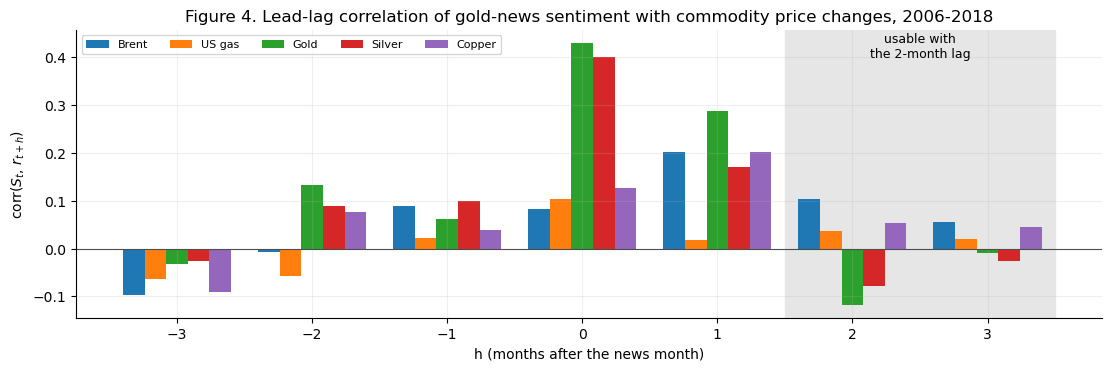

,-3,-2,-1,0,1,2,3
brent,-0.10,-0.01,0.09,0.08,0.20,0.10,0.06
natural_gas_us,-0.06,-0.06,0.02,0.10,0.02,0.04,0.02
gold,-0.03,0.13,0.06,0.43,0.29,-0.12,-0.01
silver,-0.03,0.09,0.10,0.40,0.17,-0.08,-0.03
copper,-0.09,0.08,0.04,0.13,0.20,0.05,0.04


In [12]:
lead_lag = pd.DataFrame({h: {asset: S.corr(ret[asset].shift(-h).reindex(common)) for asset in ret.columns}
                         for h in range(-3, 4)}).T
fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
width = .16
for i, asset in enumerate(ret.columns):
    ax.bar(lead_lag.index + (i - 2) * width, lead_lag[asset], width,
           label={"brent": "Brent", "natural_gas_us": "US gas"}.get(asset, asset.capitalize()))
ax.axvspan(1.5, 3.5, color=".9", zorder=0)
ax.text(2.5, .4, "usable with\nthe 2-month lag", ha="center", fontsize=9)
ax.axhline(0, color=".3", linewidth=.8)
ax.set(xlabel="h (months after the news month)", ylabel="corr($S_t$, $r_{t+h}$)",
       title="Figure 4. Lead-lag correlation of gold-news sentiment with commodity price changes, 2006-2018")
ax.legend(ncol=5, fontsize=8, loc="upper left")
plt.show()
display(lead_lag.T.round(2))

Sentiment is strongly correlated with gold and silver price changes in the same month (0.43 and 0.40). The correlation persists into the next month (0.29 for gold), partly because a monthly average price carries late-month moves into the following month. At $h=2$, the first horizon a portfolio can trade, the correlation with gold turns negative (−0.12), and it is close to zero for the other commodities. The headlines summarise moves that are already in prices, so in the regime models sentiment adds noise rather than information.

## 5. Robustness
### 5.1 Costs, bootstrap block length and the sentiment threshold
The same target weights are repriced at 0 and 25 bp, the intervals are recomputed with 3- and 12-month blocks, and G is rerun with a zero threshold instead of the development median.

In [13]:
short = {name.split("  ")[1]: pair for name, pair in PAIRS.items()}
rows = {}
for fee in [0, 10, 25]:
    fee_net = pd.DataFrame({key: backtest(weights[key], fee).net_return for key in NAMES})
    s = sharpe(fee_net)
    rows[f"Δ Sharpe, {fee} bp"] = {p: s[a] - s[b] for p, (a, b) in short.items()}
robust = pd.DataFrame(rows)
for block in [3, 6, 12]:
    b = paired_bootstrap(net, short, block=block)
    robust[f"95% interval, {block}-month blocks"] = [f"[{lo:+.2f}, {hi:+.2f}]" for lo, hi in zip(b["95% low"], b["95% high"])]
display(robust.round(3))

weights_g0, _ = allocate(ret, {"G": sentiment_states(0.0)}, test_dates, MODEL_END)
net_g0 = backtest(weights_g0["G"], FEE_BPS).net_return
print(f"G with zero threshold: Sharpe {sharpe(net_g0):.2f} (median threshold {sharpe(net['G']):.2f}; Markowitz {sharpe(net['B']):.2f})")

,"Δ Sharpe, 0 bp","Δ Sharpe, 10 bp","Δ Sharpe, 25 bp","95% interval, 3-month blocks","95% interval, 6-month blocks","95% interval, 12-month blocks"
C−B,0.348,0.335,0.315,"[+0.06, +0.82]","[+0.04, +0.81]","[+0.03, +0.79]"
E−B,0.110,0.092,0.066,"[-0.38, +0.50]","[-0.36, +0.43]","[-0.35, +0.43]"
G−B,-0.130,-0.151,-0.182,"[-0.64, +0.24]","[-0.49, +0.15]","[-0.40, +0.08]"
D−C,-0.158,-0.168,-0.184,"[-0.68, +0.08]","[-0.63, +0.06]","[-0.62, +0.07]"
F−E,-0.027,-0.028,-0.030,"[-0.09, +0.01]","[-0.08, +0.01]","[-0.08, +0.01]"


G with zero threshold: Sharpe 0.32 (median threshold 0.20; Markowitz 0.35)


Neither the cost level nor the block length changes any sign or conclusion: C−B is the only contrast whose 95% interval excludes zero in every case. G depends on its threshold (Sharpe 0.32 with a zero threshold, 0.20 with the median), but it stays below Markowitz either way.

### 5.2 Stability of the regimes
For each model we show the number of development and evaluation-signal months in each state (the GMM uses its most probable component), how often the state persists from one month to the next, the adjusted Rand index between the main fit and refits with seeds 0, 7, 21 and 99, and how often a state falls back to unconditional moments.

In [14]:
labels = pd.DataFrame({key: p.to_numpy().argmax(axis=1) for key, p in probabilities.items()}, index=common)
rows = []
for key in "CDEFG":
    k = probabilities[key].shape[1]
    y = labels.loc[signal_dates, key]
    if key in SPECS:
        algorithm, data = SPECS[key]
        ari = [adjusted_rand_score(labels.loc[dev_dates, key],
                                   fit_memberships(data, algorithm, k, dev_dates, seed).loc[dev_dates].to_numpy().argmax(axis=1))
               for seed in [0, 7, 21, 99]]
        seeds = f"{min(ari):.2f}-{max(ari):.2f}"
    else:
        seeds = "deterministic"
    fallback = audit.loc[audit.strategy.eq(key), "fallback_components"]
    rows.append({"strategy": f"{key}: {DESCRIPTIONS[key]}", "k": k,
                 "development months": ", ".join(map(str, labels.loc[dev_dates, key].value_counts().reindex(range(k), fill_value=0))),
                 "evaluation months": ", ".join(map(str, y.value_counts().reindex(range(k), fill_value=0))),
                 "persistence": f"{y.iloc[1:].eq(y.shift(1).iloc[1:]).mean():.0%}", "seed ARI": seeds,
                 "states on fallback": (f"{fallback.max()} state(s), {int(fallback.gt(0).sum())}/30 months"
                                        if fallback.max() else "none")})
display(pd.DataFrame(rows).set_index("strategy"))

,k,development months,evaluation months,persistence,seed ARI,states on fallback
strategy,,,,,,
C: KMeans regimes,3,"62, 51, 4","26, 4, 0",79%,0.93-1.00,"1 state(s), 30/30 months"
D: KMeans + sentiment,3,"54, 59, 4","6, 24, 0",66%,0.87-1.00,"1 state(s), 30/30 months"
E: GMM regimes,4,"12, 53, 12, 40","0, 18, 0, 12",62%,0.63-0.81,"1 state(s), 30/30 months"
F: GMM + sentiment,4,"12, 52, 41, 12","0, 18, 12, 0",62%,0.47-0.81,"1 state(s), 30/30 months"
G: Sentiment only,2,"59, 58","20, 10",55%,deterministic,none


The regimes are weakly separated (validation silhouette 0.17) and partly degenerate. Each KMeans model has a four-month state that never occurs during evaluation, and two GMM components are empty there, so in every month one state falls back to unconditional moments. KMeans is stable across seeds (adjusted Rand index of at least 0.87), but the GMM is not (0.47–0.81), so its states should not be read as economic regimes. Adding sentiment reassigns several KMeans evaluation months but leaves the GMM evaluation states unchanged up to relabelling: 18 and 12 months in both.

### 5.3 A second period for H1: March 2021 – December 2025
The gold corpus ends in 2018, but the regime strategies need no news. We repeat H1 with the same design shifted five years: training on April 2006 – December 2015, validation on 2016–2020, a frozen refit through December 2020, and evaluation over the 58 months from March 2021 to December 2025.

In [15]:
X2 = X_all.loc[START:"2025-12"]
model_end_2 = pd.Timestamp("2020-12-01")
test_dates_2 = pd.date_range("2021-03-01", "2025-12-01", freq="MS")
counts_2, _ = select_counts(X2, X2.loc[:"2015-12"].index, X2.loc["2016":"2020"].index)
memberships_2 = {key: fit_memberships(X2, alg, counts_2[alg], X2.loc[:model_end_2].index)
                 for key, alg in [("C", "KMeans"), ("E", "GMM")]}
weights_2, _ = allocate(ret, memberships_2, test_dates_2, model_end_2)
net_2 = pd.DataFrame({key: backtest(w, FEE_BPS).net_return for key, w in weights_2.items()})
second = paired_bootstrap(net_2, {"C−B KMeans regimes vs Markowitz": ("C", "B"),
                                  "E−B GMM regimes vs Markowitz": ("E", "B")})
second.insert(0, "Markowitz Sharpe", sharpe(net_2["B"]))
second.insert(1, "Regime Sharpe", [sharpe(net_2["C"]), sharpe(net_2["E"])])
print("Selected counts on the later sample:", counts_2)
display(second.round(3))

Selected counts on the later sample: {'KMeans': 4, 'GMM': 4}


,Markowitz Sharpe,Regime Sharpe,Sharpe difference,95% low,95% high,99% low,99% high
C−B KMeans regimes vs Markowitz,1.145,1.041,-0.104,-0.368,0.097,-0.416,0.155
E−B GMM regimes vs Markowitz,1.145,0.882,-0.263,-0.584,0.005,-0.658,0.082


In 2021–2025 the regimes **lower** the Sharpe ratio relative to Markowitz, by 0.10 for KMeans and 0.26 for GMM, and both intervals include zero. The positive KMeans result of 2016–2018 does not carry over, so across the two periods regime conditioning does not reliably improve on Markowitz.

### 5.4 Computational checks
Look-ahead test: for every evaluation month, all returns and memberships after the information cutoff are replaced with random values, and the recomputed weights must not change. The backtest cash flows are also rebuilt independently.

In [16]:
rng = np.random.default_rng(2026)
for date in test_dates:
    cutoff = date - pd.DateOffset(months=LAG)
    fake_ret = ret.copy()
    future = fake_ret.index > cutoff
    fake_ret.loc[future] = rng.uniform(-.4, .5, size=(future.sum(), ret.shape[1]))
    fake_p = {}
    for key, p in probabilities.items():
        fake_p[key] = p.copy()
        fake_p[key].loc[p.index > cutoff] = rng.dirichlet(np.ones(p.shape[1]), size=(p.index > cutoff).sum())
    replay, _ = allocate(fake_ret, fake_p, pd.DatetimeIndex([date]), MODEL_END)
    for key in NAMES:
        np.testing.assert_allclose(replay[key].loc[date], weights[key].loc[date], rtol=0, atol=1e-10)

for key, w in weights.items():
    r = ret.loc[test_dates, w.columns]
    gross = (w * r).sum(axis=1)
    drifted = w.mul(1 + r).div(1 + gross, axis=0).shift(1).fillna(0)
    turnover = (w - drifted).abs().sum(axis=1)
    np.testing.assert_allclose(net[key], (1 - FEE_BPS / 1e4 * turnover) * (1 + gross) - 1, atol=1e-12)
print("PASS: future data cannot change any of the 30 x 7 allocations; cash flows reconcile.")

PASS: future data cannot change any of the 30 x 7 allocations; cash flows reconcile.


## 6. Conclusion
**Answer to the research question.** For five commodities over July 2016 – December 2018, neither source of information reliably improves a constrained Markowitz allocation. KMeans market regimes give the best Sharpe ratio (0.68 against 0.35), but the gain is not significant once five tests are taken into account, and it reverses in 2021–2025. Gold-news sentiment does not help, either alone or combined with regimes. The lead-lag analysis explains why: the annotated headlines describe gold prices that have already moved, and once the publication lag is respected nothing is left to forecast.

**Limitations.** World Bank monthly averages are price proxies, not futures total returns: they omit roll yield, collateral return and executable prices. The data are revised snapshots, not point-in-time vintages; the dollar index, for example, was defined in February 2019 and backfilled. The 30 evaluation months had already been examined during the project, and the news covers gold only, although gold is the largest holding, close to 60%.

**Further work.** Use news that looks forward rather than back (for example, headlines flagged as future information, or a longer LLM-scored oil and metals corpus), replace price proxies with futures total returns, and evaluate on dates not used during development.

### References and implementation attribution
- World Bank, *Commodity Price Data (Pink Sheet)*, and FRED series VIXCLS, DTWEXBGS, DGS10 and DGS2; provider links and immutable download hashes appear in Section 2.
- Sinha, A. and Khandait, T. (2020), [*Impact of News on the Commodity Market: Dataset and Results*](https://arxiv.org/abs/2009.04202); SaguaroCapital's pinned redistribution and licence are cited in Section 2.2.
- von Beschwitz, B., Collins, C. G. and Datta, D. D. (2019), [*Revisions to the Federal Reserve Dollar Indexes*](https://www.federalreserve.gov/econres/notes/feds-notes/revisions-to-the-federal-reserve-dollar-indexes-20190115.html), Federal Reserve Board.
- Champonnois, S. (2026), [*Machine-learning for Portfolio Management and Trading: An Introduction with Scikit-Learn*](https://github.com/schampon/skfin/blob/master/book/book.pdf), Chapters 4 (backtesting), 9 (covariance shrinkage), 15 (transaction costs), 27 (performance and risk metrics) and 30 (empirical research presentation).
- Champonnois, S., [*ML for Portfolio Management and Trading — course notebooks*](https://github.com/schampon/skfin/tree/master/nbs): `10_Mean_variance_estimators`, `11_Backtesting`, `19_Hyperparameter_optimisation`, `30_Transaction_cost`, `41_Timing_backtest_with_learning`, `46_Text_processing` and `92_Project_template`. These inform mean–variance allocation, chronological evaluation, text aggregation and presentation; this project retains its own fixed allocation and cost conventions.
- Jdey, O. and Rou, S., project notebooks 01–05. The commodity/FRED features, seven numerical portfolio functions, news-cleaning rules and final experimental design are reused here. All code needed to reproduce them is included above; the original notebooks are not runtime dependencies.